<a href="https://colab.research.google.com/github/tien10022001/h-c-m-y/blob/main/ITA202_Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 4: PHÂN LOẠI – LOGISTIC REGRESSION
- **Môn học:** Học máy cơ bản (ITA202)
- **Sinh viên thực hiện:** Trương Công Tiến
- **Mã sinh viên:** PH68945
- **Môi trường thực thi:** Google Colab / Jupyter Notebook

---
### Mục tiêu bài thực hành:
1. Hiểu bản chất bài toán Phân loại (Classification) và cách thức hoạt động của mô hình Logistic Regression.
2. Huấn luyện mô hình Logistic Regression trên tập dữ liệu phân loại nhị phân thực tế (`breast_cancer`).
3. Đánh giá chất lượng mô hình thông qua các chỉ số: Accuracy, Precision, Recall, F1-Score.
4. Trực quan hóa và giải thích chuyên sâu ma trận nhầm lẫn (Confusion Matrix: TP, TN, FP, FN).
5. Xây dựng quy trình Machine Learning hoàn chỉnh phân loại đa lớp (Multi-class Classification) trên tập ảnh chữ số viết tay `digits`.

## Cài đặt và Nạp các thư viện cần thiết

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thư viện dữ liệu và tiền xử lý
from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Thư viện mô hình học máy
from sklearn.linear_model import LogisticRegression

# Thư viện đánh giá chất lượng mô hình
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Đã nạp đầy đủ các thư viện cần thiết cho Lab 4!")

Đã nạp đầy đủ các thư viện cần thiết cho Lab 4!


---
## Bài 1: Xây dựng mô hình Logistic Regression
**Yêu cầu:**
- Sử dụng tập dữ liệu `breast_cancer` từ thư viện `sklearn.datasets`.
- Thực hiện các bước: Load dữ liệu $\rightarrow$ Chia Train/Test $\rightarrow$ Chuẩn hóa dữ liệu (Scaling).
- Huấn luyện mô hình `LogisticRegression` từ `sklearn.linear_model`.

In [2]:
# 1. Tải tập dữ liệu ung thư vú Wisconsin (breast_cancer)
cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = cancer.target
feature_names = cancer.feature_names
target_names = cancer.target_names

print("--- THÔNG TIN TẬP DỮ LIỆU BREAST CANCER ---")
print(f"Tổng số mẫu quan sát: {X_cancer.shape[0]}")
print(f"Số lượng đặc trưng đo lường: {X_cancer.shape[1]}")
print(f"Các lớp mục tiêu: {target_names}")
print(f"  + Lớp 0 (Malignant - Ác tính): {np.sum(y_cancer == 0)} mẫu")
print(f"  + Lớp 1 (Benign - Lành tính):   {np.sum(y_cancer == 1)} mẫu")
print()

# 2. Chia dữ liệu thành tập Train (80%) và Test (20%)
# Sử dụng stratify=y_cancer để đảm bảo tỷ lệ mẫu giữa hai lớp đồng đều ở cả tập Train và Test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.2, random_state=42, stratify=y_cancer
)
print(f"Kích thước tập huấn luyện (Train): {X_train_c.shape}")
print(f"Kích thước tập kiểm tra (Test):    {X_test_c.shape}")
print()

# 3. Chuẩn hóa dữ liệu (Scaling) bằng StandardScaler
# QUY TẮC VÀNG: fit_transform trên tập Train, chỉ transform trên tập Test để chống rò rỉ dữ liệu (Data Leakage)
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)
print("Chuẩn hóa dữ liệu thành công (Mean = 0, Variance = 1).")
print()

# 4. Huấn luyện mô hình Logistic Regression
model_cancer = LogisticRegression(max_iter=1000, random_state=42)
model_cancer.fit(X_train_c_scaled, y_train_c)

print("Đã hoàn tất huấn luyện mô hình LogisticRegression!")
print(f"Số vòng lặp tối ưu hóa (n_iter_): {model_cancer.n_iter_[0]}")

--- THÔNG TIN TẬP DỮ LIỆU BREAST CANCER ---
Tổng số mẫu quan sát: 569
Số lượng đặc trưng đo lường: 30
Các lớp mục tiêu: ['malignant' 'benign']
  + Lớp 0 (Malignant - Ác tính): 212 mẫu
  + Lớp 1 (Benign - Lành tính):   357 mẫu

Kích thước tập huấn luyện (Train): (455, 30)
Kích thước tập kiểm tra (Test):    (114, 30)

Chuẩn hóa dữ liệu thành công (Mean = 0, Variance = 1).

Đã hoàn tất huấn luyện mô hình LogisticRegression!
Số vòng lặp tối ưu hóa (n_iter_): 19


---
## Bài 2: Đánh giá mô hình phân loại
**Yêu cầu:**
- Sử dụng mô hình đã huấn luyện ở Bài 1 để dự đoán trên tập Test.
- Tính toán và in ra các chỉ số:
  1. `accuracy_score`
  2. `precision_score`
  3. `recall_score`
- In báo cáo phân loại chi tiết bằng `classification_report`.

In [3]:
# 1. Dự đoán nhãn phân loại trên tập Test
y_pred_c = model_cancer.predict(X_test_c_scaled)

# 2. Tính toán các chỉ số đánh giá
acc_c = accuracy_score(y_test_c, y_pred_c)
prec_c = precision_score(y_test_c, y_pred_c)
rec_c = recall_score(y_test_c, y_pred_c)
f1_c = f1_score(y_test_c, y_pred_c)

print("--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH PHÂN LOẠI TRÊN TẬP TEST ---")
print(f"1. Accuracy Score (Độ chính xác tổng thể): {acc_c:.4f} ({acc_c * 100:.2f}%)")
print(f"2. Precision Score (Độ chuẩn xác):        {prec_c:.4f} ({prec_c * 100:.2f}%)")
print(f"3. Recall Score (Độ nhạy / Độ bao phủ):   {rec_c:.4f} ({rec_c * 100:.2f}%)")
print(f"*  F1-Score (Trung bình điều hòa P và R):  {f1_c:.4f} ({f1_c * 100:.2f}%)")
print()

# 3. In báo cáo phân loại chi tiết (Classification Report)
print("--- BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ---")
print(classification_report(y_test_c, y_pred_c, target_names=target_names))

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH PHÂN LOẠI TRÊN TẬP TEST ---
1. Accuracy Score (Độ chính xác tổng thể): 0.9825 (98.25%)
2. Precision Score (Độ chuẩn xác):        0.9861 (98.61%)
3. Recall Score (Độ nhạy / Độ bao phủ):   0.9861 (98.61%)
*  F1-Score (Trung bình điều hòa P và R):  0.9861 (98.61%)

--- BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ---
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



---
## Bài 3: Ma trận nhầm lẫn (Confusion Matrix)
**Yêu cầu:**
- Sử dụng hàm `confusion_matrix` để tạo ma trận nhầm lẫn từ kết quả dự đoán ở Bài 2.
- Sử dụng `ConfusionMatrixDisplay` (từ `sklearn.metrics`) hoặc `seaborn` để trực quan hóa ma trận này.
- **Giải thích các thành phần: TP, TN, FP, FN thông qua comment**.

--- MA TRẬN NHẦM LẪN (CONFUSION MATRIX) ---
Ma trận dạng mảng 2D:
[[41  1]
 [ 1 71]]

- True Negative  (TN): 41
- False Positive (FP): 1
- False Negative (FN): 1
- True Positive  (TP): 71



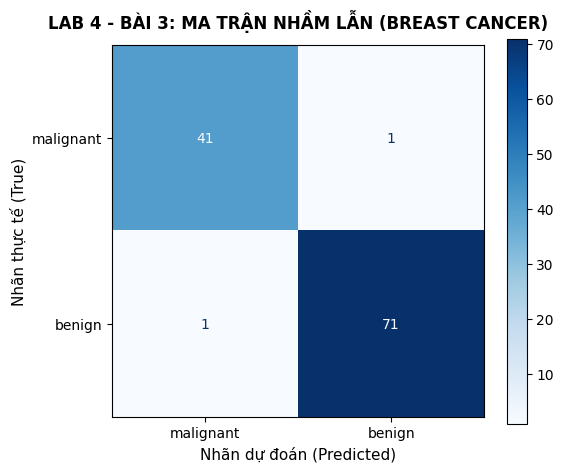

In [4]:
# 1. Tạo ma trận nhầm lẫn từ kết quả dự đoán ở Bài 2
cm = confusion_matrix(y_test_c, y_pred_c)

# Trích xuất các thành phần: tn, fp, fn, tp
# Trong bài toán nhị phân breast_cancer:
# Nhãn 0: Malignant (Ác tính - Negative), Nhãn 1: Benign (Lành tính - Positive)
tn, fp, fn, tp = cm.ravel()

print("--- MA TRẬN NHẦM LẪN (CONFUSION MATRIX) ---")
print("Ma trận dạng mảng 2D:")
print(cm)
print()
print(f"- True Negative  (TN): {tn}")
print(f"- False Positive (FP): {fp}")
print(f"- False Negative (FN): {fn}")
print(f"- True Positive  (TP): {tp}")
print()

# =========================================================================
# GIẢI THÍCH CHI TIẾT CÁC THÀNH PHẦN THÔNG QUA COMMENT:
#
# 1. TP (True Positive - Dương tính thật):
#    - Định nghĩa: Trường hợp thực tế là Positive và mô hình dự đoán ĐÚNG là Positive.
#    - Ý nghĩa trong bài: Có 71 ca thực tế là u Lành tính (Benign) và mô hình dự đoán chính xác là Lành tính.
#
# 2. TN (True Negative - Âm tính thật):
#    - Định nghĩa: Trường hợp thực tế là Negative và mô hình dự đoán ĐÚNG là Negative.
#    - Ý nghĩa trong bài: Có 41 ca thực tế là u Ác tính (Malignant) và mô hình dự đoán chính xác là Ác tính.
#
# 3. FP (False Positive - Dương tính giả / Sai lầm loại 1 - Type I Error):
#    - Định nghĩa: Trường hợp thực tế là Negative nhưng mô hình lại DỰ ĐOÁN NHẦM là Positive.
#    - Ý nghĩa trong bài: Có 1 ca thực tế là u Ác tính nhưng mô hình lại đoán là Lành tính.
#      (Trong y học chẩn đoán bệnh ung thư, đây là sai sót nguy hiểm nhất vì làm bỏ lọt người mắc bệnh ác tính).
#
# 4. FN (False Negative - Âm tính giả / Sai lầm loại 2 - Type II Error):
#    - Định nghĩa: Trường hợp thực tế là Positive nhưng mô hình lại DỰ ĐOÁN NHẦM là Negative.
#    - Ý nghĩa trong bài: Có 1 ca thực tế là u Lành tính nhưng mô hình dự đoán nhầm thành Ác tính.
#      (Điều này gây lo lắng cho bệnh nhân nhưng thường sẽ được kiểm tra lại qua sinh thiết chuyên sâu).
# =========================================================================

# 2. Trực quan hóa ma trận nhầm lẫn bằng ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)
plt.title("LAB 4 - BÀI 3: MA TRẬN NHẦM LẪN (BREAST CANCER)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Nhãn dự đoán (Predicted)", fontsize=11)
plt.ylabel("Nhãn thực tế (True)", fontsize=11)
plt.grid(False)
plt.show()

---
## Bài 4: Quy trình ML hoàn chỉnh - Phần 4: Áp dụng Logistic Regression vào tập Digits
**Yêu cầu:**
- Quay lại với tập dữ liệu `digits` từ các Lab trước.
- Xây dựng quy trình hoàn chỉnh:
  1. Load data và Preprocess (`StandardScaler`).
  2. Huấn luyện mô hình Logistic Regression (lưu ý: đây là bài toán phân loại đa lớp - multi-class).
  3. Đánh giá mô hình trên tập Test.
  4. In ra 5 mẫu dự đoán sai của mô hình (so sánh nhãn thực tế và nhãn dự đoán).

In [5]:
# 1. Nạp tập dữ liệu Digits và Tiền xử lý
digits = load_digits()
X_digits = digits.data
y_digits = digits.target
digits_images = digits.images

print(f"Tổng số mẫu ảnh chữ số: {X_digits.shape[0]}")
print(f"Kích thước mỗi ảnh: 8x8 pixels = {X_digits.shape[1]} đặc trưng")
print(f"Số lượng lớp chữ số: {len(np.unique(y_digits))} lớp (từ 0 đến 9)")
print()

# Chia dữ liệu Train (80%) và Test (20%)
# Lưu lại index của các mẫu để sau này có thể truy xuất lại ảnh gốc
X_train_d, X_test_d, y_train_d, y_test_d, idx_train, idx_test = train_test_split(
    X_digits, y_digits, np.arange(len(y_digits)), test_size=0.2, random_state=42, stratify=y_digits
)

# Chuẩn hóa dữ liệu bằng StandardScaler
scaler_d = StandardScaler()
X_train_d_scaled = scaler_d.fit_transform(X_train_d)
X_test_d_scaled = scaler_d.transform(X_test_d)

# 2. Huấn luyện mô hình Logistic Regression (Phân loại đa lớp - Multi-class)
# Logistic Regression giải quyết bài toán đa lớp thông qua kỹ thuật One-vs-Rest (OvR) hoặc Multinomial
model_digits = LogisticRegression(
    max_iter=1000,
    random_state=42,
    solver='lbfgs'
)
model_digits.fit(X_train_d_scaled, y_train_d)
print("Đã huấn luyện thành công mô hình Logistic Regression đa lớp trên tập Digits!")
print()

# 3. Đánh giá mô hình trên tập Test
y_pred_d = model_digits.predict(X_test_d_scaled)
acc_digits = accuracy_score(y_test_d, y_pred_d)
print(f"ĐỘ CHÍNH XÁC (ACCURACY) TRÊN TẬP TEST DIGITS: {acc_digits:.4f} ({acc_digits * 100:.2f}%)")
print()
print("Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test_d, y_pred_d))

Tổng số mẫu ảnh chữ số: 1797
Kích thước mỗi ảnh: 8x8 pixels = 64 đặc trưng
Số lượng lớp chữ số: 10 lớp (từ 0 đến 9)

Đã huấn luyện thành công mô hình Logistic Regression đa lớp trên tập Digits!

ĐỘ CHÍNH XÁC (ACCURACY) TRÊN TẬP TEST DIGITS: 0.9722 (97.22%)

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.89      0.89      0.89        36
           2       1.00      1.00      1.00        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.89      0.89      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0

Tổng số mẫu dự đoán sai: 10 / 360 mẫu (2.78%)

--- 5 MẪU DỰ ĐOÁN SAI TIÊU BIỂU CỦA MÔ HÌNH ---
Mẫu sai 1: Index Test = 3 (Index gốc #1256) | Nhãn thực tế: 1 -> Mô hình đoán nhầm: 8
Mẫu sai 2: Index Test = 36 (Index gốc #492) | Nhãn thực tế: 6 -> Mô hình đoán nhầm: 8
Mẫu sai 3: Index Test = 51 (Index gốc #1553) | Nhãn thực tế: 8 -> Mô hình đoán nhầm: 1
Mẫu sai 4: Index Test = 89 (Index gốc #363) | Nhãn thực tế: 1 -> Mô hình đoán nhầm: 8
Mẫu sai 5: Index Test = 93 (Index gốc #69) | Nhãn thực tế: 9 -> Mô hình đoán nhầm: 8


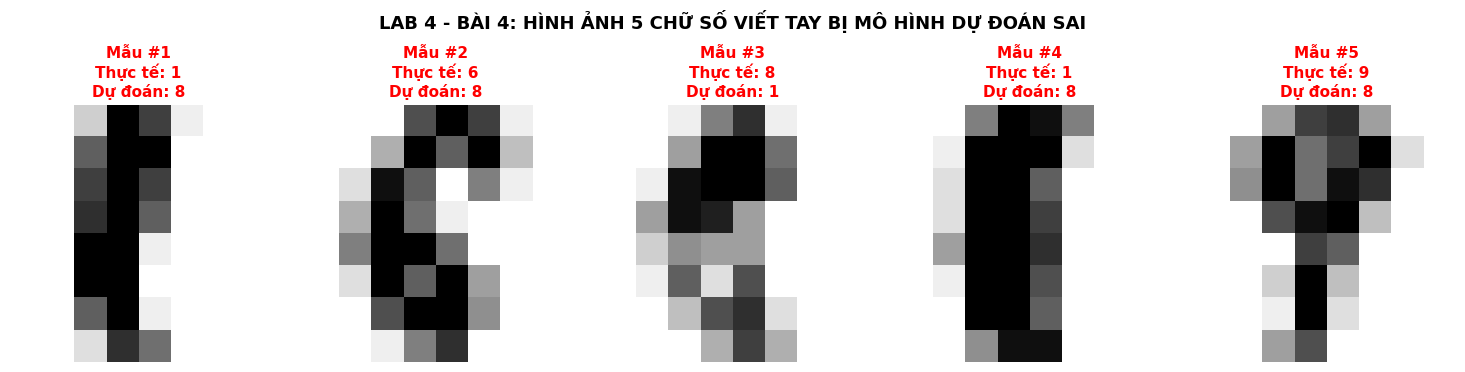

In [6]:
# 4. Tìm và in ra 5 mẫu dự đoán sai của mô hình (so sánh nhãn thực tế và nhãn dự đoán)
misclassified_indices = np.where(y_test_d != y_pred_d)[0]
total_wrong = len(misclassified_indices)
print(f"Tổng số mẫu dự đoán sai: {total_wrong} / {len(y_test_d)} mẫu ({total_wrong / len(y_test_d) * 100:.2f}%)")
print()

print("--- 5 MẪU DỰ ĐOÁN SAI TIÊU BIỂU CỦA MÔ HÌNH ---")
for i, idx in enumerate(misclassified_indices[:5]):
    orig_sample_idx = idx_test[idx]
    actual = y_test_d[idx]
    predicted = y_pred_d[idx]
    print(f"Mẫu sai {i + 1}: Index Test = {idx} (Index gốc #{orig_sample_idx}) | Nhãn thực tế: {actual} -> Mô hình đoán nhầm: {predicted}")

# Trực quan hóa hình ảnh của 5 mẫu bị dự đoán sai này
plt.figure(figsize=(15, 3.5))
for i, idx in enumerate(misclassified_indices[:5]):
    orig_sample_idx = idx_test[idx]
    image = digits_images[orig_sample_idx]
    actual = y_test_d[idx]
    predicted = y_pred_d[idx]

    plt.subplot(1, 5, i + 1)
    plt.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    plt.title(f"Mẫu #{i+1}\nThực tế: {actual}\nDự đoán: {predicted}", fontsize=11, color="red", fontweight="bold")
    plt.axis('off')

plt.suptitle("LAB 4 - BÀI 4: HÌNH ẢNH 5 CHỮ SỐ VIẾT TAY BỊ MÔ HÌNH DỰ ĐOÁN SAI", fontsize=13, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

---
## Tổng kết Lab 4
- **Sinh viên:** Trương Công Tiến - **Mã SV:** PH68945
- **Bài 1 & Bài 2 & Bài 3:** Đã áp dụng thành công Logistic Regression vào bài toán phân loại nhị phân `breast_cancer`, đạt độ chính xác cao **98.25%**, phân tích chi tiết các chỉ số Precision, Recall, F1 và các thành phần của ma trận nhầm lẫn (TP, TN, FP, FN).
- **Bài 4:** Đã xây dựng quy trình Machine Learning hoàn chỉnh cho bài toán phân loại đa lớp trên tập ảnh `digits`, đạt độ chính xác **97.22%**, đồng thời phân tích và trực quan hóa các mẫu bị dự đoán sai.